<a href="https://colab.research.google.com/github/rayhankwarta/tugas-akhir/blob/main/TA_MohammadRayhanKwartaNauval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🥗 Segmentasi Pola Asupan Gizi Harian Mahasiswa
## Universitas Mercubuana — K-Means Clustering
### Kebutuhan Energi Individual: Harris-Benedict Revised (Roza & Shizgal, 1984)

---
**Rumusan Masalah:**
1. Bagaimana pola distribusi asupan gizi harian mahasiswa berdasarkan data NutriTrack?
2. Bagaimana K-Means mengelompokkan mahasiswa berdasarkan kesamaan pola asupan gizinya?
3. Bagaimana karakteristik dan perbedaan profil setiap segmen (cluster) yang terbentuk?

---
**Formula Harris-Benedict Revised — Roza & Shizgal (1984):**

| Gender | BMR Formula |
|--------|-------------|
| **Pria** | 88.362 + (13.397 × BB) + (4.799 × TB) − (5.677 × Usia) |
| **Wanita** | 447.593 + (9.247 × BB) + (3.098 × TB) − (4.330 × Usia) |

**Activity Multiplier (PAL):**
| Level | Faktor | Deskripsi |
|-------|--------|-----------|
| Sedentary | 1.200 | Tidak/jarang olahraga |
| Light | 1.375 | Olahraga ringan 1–3x/minggu |
| Moderate | 1.550 | Olahraga sedang 3–5x/minggu |

> TEE (Total Energy Expenditure) = BMR × PAL


**Import Library & Setup**


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import warnings

# Meredam warning dari sklearn agar output tetap bersih
warnings.filterwarnings('ignore')

# Set tema visual grafik ala jurnal ilmiah
sns.set_theme(style="whitegrid")
print("Library berhasil dimuat.")

Library berhasil dimuat.


**Data Selection (Load Dataset)**

In [ ]:
print("--- TAHAP 2: LOADING DATASET ---")
file_path = '/content/Data_Gizi_Lengkap_Gender_Updated.xlsx'
df = pd.read_excel(file_path)

print(f"Berhasil memuat data. Total records awal: {df.shape[0]} baris, {df.shape[1]} kolom.")
print("\nPreview 5 data teratas:")
df.head()

--- TAHAP 2: LOADING DATASET ---
Berhasil memuat data. Total records awal: 442 baris, 14 kolom.

Preview 5 data teratas:


,User ID,Nama Mahasiswa,Umur,Tinggi Badan,Berat Badan,Tingkat Aktivitas,Food Name,Kalori,Karbo,Protein,Lemak,Meal food,Tanggal,gender
0,6a03242031722f1efa782353,Nauval Azis Prasetio,20,170,60,sedentary,Tumis Sayuran,299,53.58,7.0,5.24,Lunch,12/05/2026,Male
1,6a03242031722f1efa782353,Nauval Azis Prasetio,20,170,60,sedentary,Nasi Pecel,496,75.50,18.0,13.20,Breakfast,12/05/2026,Male
2,6a03242031722f1efa782353,Nauval Azis Prasetio,20,170,60,sedentary,Mie Instan,390,53.00,8.0,16.00,Dinner,12/05/2026,Male
3,6a03242031722f1efa782353,Nauval Azis Prasetio,20,170,60,sedentary,Ayam Suwir,379,46.88,27.7,8.24,Breakfast,13/05/2026,Male
4,6a03242031722f1efa782353,Nauval Azis Prasetio,20,170,60,sedentary,Rawon Daging Sapi,388,38.20,22.7,15.50,Lunch,13/05/2026,Male


--- TAHAP AWAL: VISUALISASI DISTRIBUSI MAKRONUTRIEN DARI DATA MENTAH ---


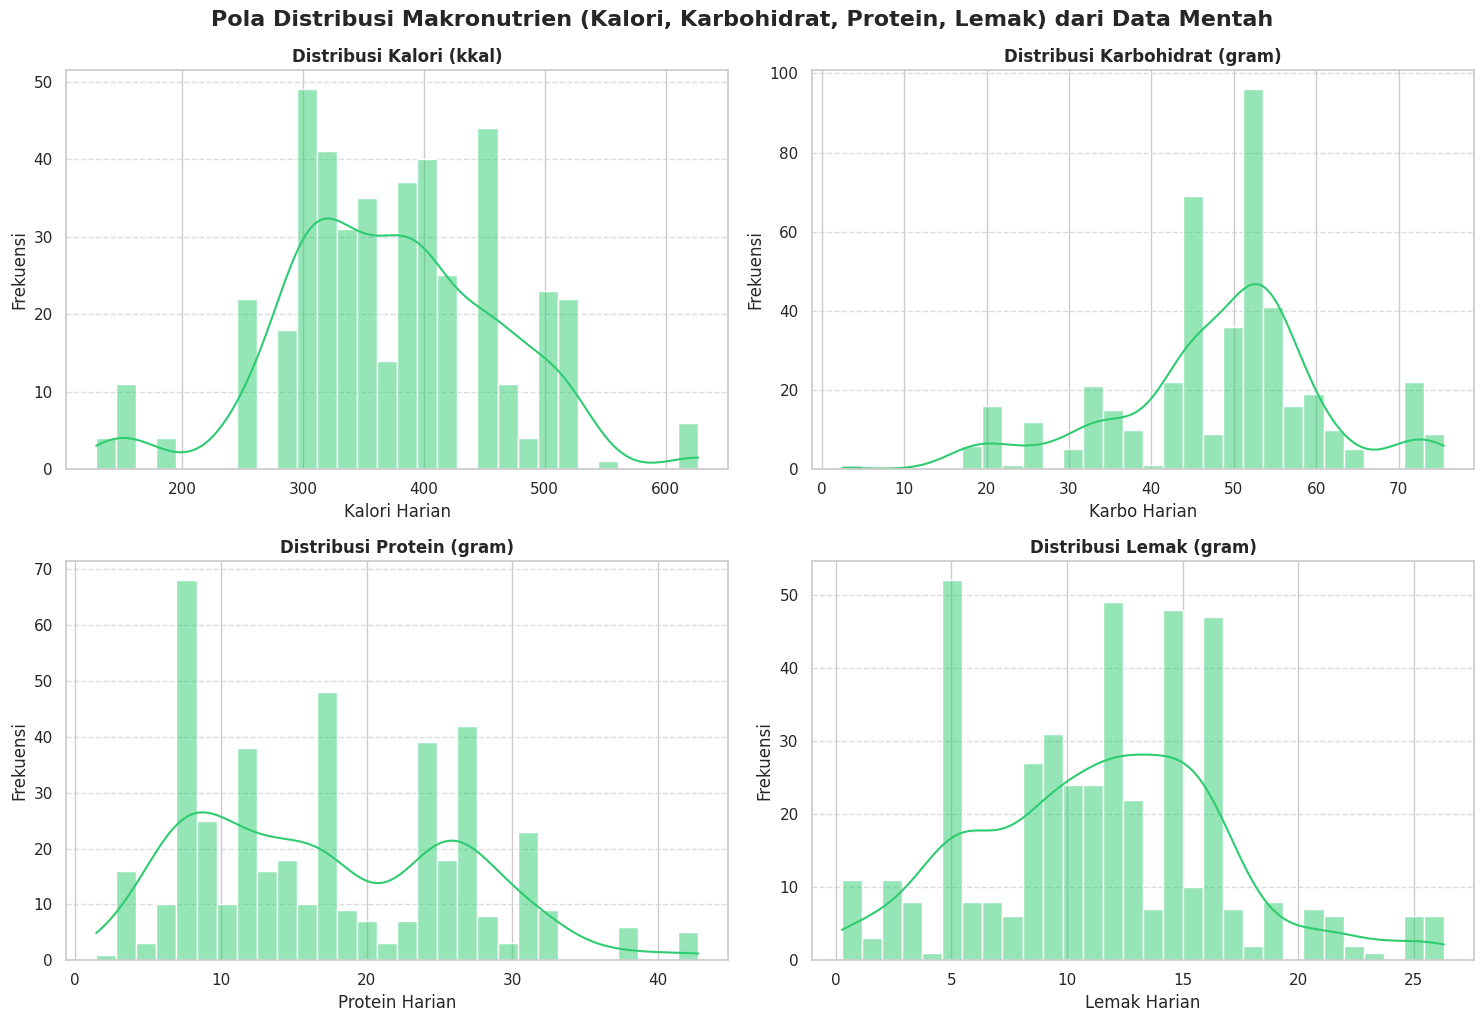

Visualisasi distribusi awal makronutrien telah berhasil dibuat.


In [ ]:
print("--- TAHAP AWAL: VISUALISASI DISTRIBUSI MAKRONUTRIEN DARI DATA MENTAH ---")

macronutrients_raw = ['Kalori', 'Karbo', 'Protein', 'Lemak']
macronutrient_labels_raw = {
    'Kalori': 'Distribusi Kalori (kkal)',
    'Karbo': 'Distribusi Karbohidrat (gram)',
    'Protein': 'Distribusi Protein (gram)',
    'Lemak': 'Distribusi Lemak (gram)'
}

plt.figure(figsize=(15, 10))

for i, macro in enumerate(macronutrients_raw):
    plt.subplot(2, 2, i + 1)
    sns.histplot(
        x=macro,
        data=df,
        kde=True,
        color='#2ecc71', # Hijau
        bins=30
    )
    plt.title(f'{macronutrient_labels_raw[macro]}', fontsize=12, fontweight='bold')
    plt.xlabel(f'{macro} Harian')
    plt.ylabel('Frekuensi')
    plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.suptitle('Pola Distribusi Makronutrien (Kalori, Karbohidrat, Protein, Lemak) dari Data Mentah', fontsize=16, fontweight='bold', y=1.02)
plt.show()

print("Visualisasi distribusi awal makronutrien telah berhasil dibuat.")

--- TAHAP DETEKSI OUTLIER VISUAL (BOX PLOT) ---



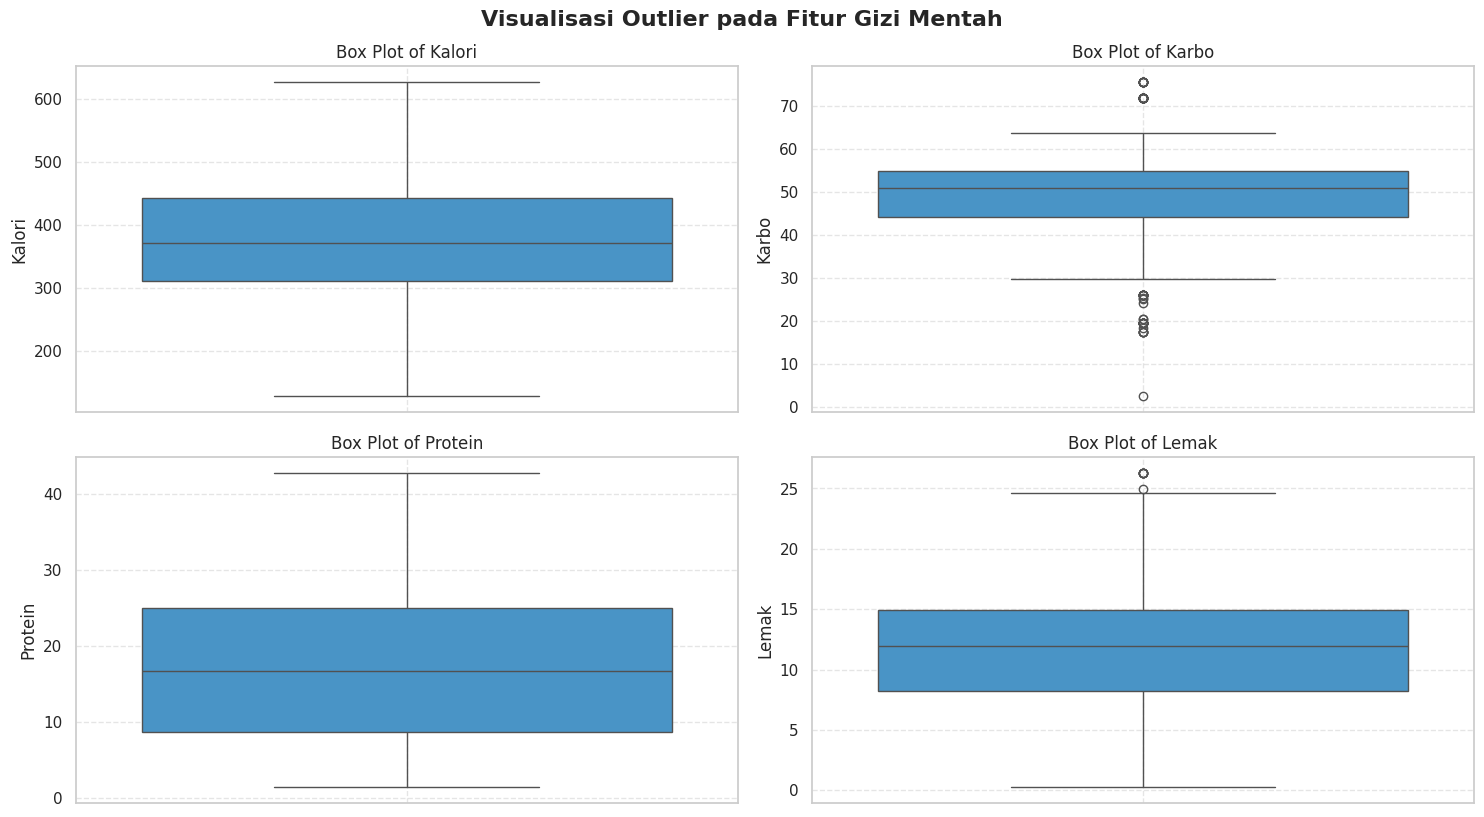

Analisis visual outlier pada data gizi mentah telah ditampilkan. Titik-titik di luar 'whisker' box plot menunjukkan potensi outlier.


In [ ]:
print("--- TAHAP DETEKSI OUTLIER VISUAL (BOX PLOT) ---\n")

# Fitur-fitur utama dari data mentah yang akan diperiksa outlier-nya
# Menggunakan kolom 'Kalori', 'Karbo', 'Protein', 'Lemak' dari df
features_to_check_raw = ['Kalori', 'Karbo', 'Protein', 'Lemak']

plt.figure(figsize=(15, 8))
for i, feature in enumerate(features_to_check_raw):
    plt.subplot(2, 2, i + 1) # Membuat 2x2 grid untuk box plot
    sns.boxplot(y=df[feature], color='#3498db')
    plt.title(f'Box Plot of {feature.replace("_", " ").title()}')
    plt.ylabel(feature.replace("_", " ").title())
    plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.suptitle('Visualisasi Outlier pada Fitur Gizi Mentah', fontsize=16, fontweight='bold', y=1.02)
plt.show()

print("Analisis visual outlier pada data gizi mentah telah ditampilkan. Titik-titik di luar "
      "'whisker' box plot menunjukkan potensi outlier.")

**Data Preprocessing**

In [ ]:
print("--- TAHAP PREPROCESSING (FILTERING MINIMUM LOG HARI) ---")

# Menghitung berapa banyak hari/baris log yang dimiliki oleh setiap user
user_log_counts = df['User ID'].value_counts()

# Menentukan user_id yang memiliki log minimal 3 hari
valid_user_ids = user_log_counts[user_log_counts >= 3].index

# Memfilter dataframe mentah, hanya menyisakan user yang valid
df_filtered_days = df[df['User ID'].isin(valid_user_ids)].copy()

print(f"Jumlah User Awal            : {df['User ID'].nunique()} orang")
print(f"Jumlah User Terfilter (<3H) : {df['User ID'].nunique() - len(valid_user_ids)} orang")
print(f"Jumlah User Aktif Valid (\u22653H): {len(valid_user_ids)} orang")
print(f"Sisa baris log setelah filter: {len(df_filtered_days)} baris (Dibuang: {len(df) - len(df_filtered_days)} baris)")

--- TAHAP PREPROCESSING (FILTERING MINIMUM LOG HARI) ---
Jumlah User Awal            : 22 orang
Jumlah User Terfilter (<3H) : 1 orang
Jumlah User Aktif Valid (≥3H): 21 orang
Sisa baris log setelah filter: 441 baris (Dibuang: 1 baris)


In [ ]:
print("\n--- Cek Missing Values --- ")
missing_values = df_filtered_days.isnull().sum()
missing_values = missing_values[missing_values > 0]
if not missing_values.empty:
    print("Kolom dengan Missing Values:")
    print(missing_values)
else:
    print("Tidak ada missing values dalam dataframe.")


--- Cek Missing Values --- 
Tidak ada missing values dalam dataframe.


In [ ]:
print("--- TAHAP DATA TRANSFORMATION (AGREGASI & ATWATER SYSTEM) ---")

# 1. MAPPING TEKS TINGKAT AKTIVITAS MENJADI ANGKA PAL (ROZA & SHIZGAL)
activity_map = {
    'sedentary': 1.200,
    'light': 1.375,
    'moderate': 1.550
}
df_filtered_days['faktor_aktivitas'] = df_filtered_days['Tingkat Aktivitas'].str.strip().str.lower().map(activity_map)

# 2. MASUKKAN 'faktor_aktivitas' KE DALAM KOLOM IDENTITAS FISIK YANG KONSTAN
identity_physique_cols = ['User ID', 'Nama Mahasiswa', 'gender', 'Berat Badan', 'Tinggi Badan', 'Umur', 'faktor_aktivitas']

# Kolom gizi makro yang akan dicari nilai rata-rata (mean) hariannya
agg_features = {
    'Karbo': 'mean',
    'Protein': 'mean',
    'Lemak': 'mean'
}

# Jalankan proses GroupBy
df_user = df_filtered_days.groupby(identity_physique_cols, as_index=False).agg(agg_features)

# Hitung Kalori Konsumsi Rata-rata menggunakan Koefisien Atwater
df_user['kalori_konsumsi'] = (df_user['Karbo'] * 4) + (df_user['Protein'] * 4) + (df_user['Lemak'] * 9)

print(f"Agregasi sukses! Data tingkat aktivitas berhasil dikonversi ke numerik.")
print(f"Struktur matriks data baru: {df_user.shape[0]} baris (mahasiswa).")
df_user[['Nama Mahasiswa', 'faktor_aktivitas', 'Karbo', 'Protein', 'Lemak', 'kalori_konsumsi']].head()

--- TAHAP DATA TRANSFORMATION (AGREGASI & ATWATER SYSTEM) ---
Agregasi sukses! Data tingkat aktivitas berhasil dikonversi ke numerik.
Struktur matriks data baru: 21 baris (mahasiswa).


,Nama Mahasiswa,faktor_aktivitas,Karbo,Protein,Lemak,kalori_konsumsi
0,Nauval Azis Prasetio,1.200,48.196190,16.998095,11.692381,366.008571
1,Vicky Ardiansyah,1.375,54.492381,15.143333,10.604286,373.981429
2,Ivan Kohandi,1.375,46.135714,17.316190,10.956667,352.417619
3,Defina Paridah,1.375,44.799048,15.694762,9.400476,326.579524
4,Muhammad Alfa Fauzan,1.375,42.040952,18.712857,11.480000,346.335238


In [ ]:
print("--- TAHAP DATA TRANSFORMATION (HARRIS-BENEDICT REVISED 1984) ---")

def hitung_harris_benedict_revised(row):
    gender = str(row['gender']).strip().lower()
    bb = float(row['Berat Badan'])
    tb = float(row['Tinggi Badan'])
    usia = int(row['Umur'])

    # Langsung ambil nilainya karena kolom sudah dijamin ada berkat perbaikan Cell 7
    aktivitas = float(row['faktor_aktivitas'])

    # EKSEKUSI FORMULA ROZA & SHIZGAL (1984)
    if gender in ['pria', 'laki-laki', 'male', 'l']:
        bmr = 88.362 + (13.397 * bb) + (4.799 * tb) - (5.677 * usia)
    else:
        bmr = 447.593 + (9.247 * bb) + (3.098 * tb) - (4.330 * usia)

    return bmr # Hanya kembalikan bmr

# Terapkan fungsi matematika ke dataframe
df_user['bmr'] = df_user.apply(hitung_harris_benedict_revised, axis=1)

print("Kalkulasi parameter biologis Harris-Benedict selesai disusun.")
df_user[['Nama Mahasiswa', 'kalori_konsumsi', 'bmr']].head()

--- TAHAP DATA TRANSFORMATION (HARRIS-BENEDICT REVISED 1984) ---
Kalkulasi parameter biologis Harris-Benedict selesai disusun.


,Nama Mahasiswa,kalori_konsumsi,bmr
0,Nauval Azis Prasetio,366.008571,1594.472
1,Vicky Ardiansyah,373.981429,1780.152
2,Ivan Kohandi,352.417619,1863.534
3,Defina Paridah,326.579524,1524.370
4,Muhammad Alfa Fauzan,346.335238,1774.475


In [ ]:
print("--- Kalkulasi TDEE (Total Daily Energy Expenditure) ---")

# Hitung TDEE menggunakan BMR dan faktor aktivitas
df_user['tdee'] = df_user['bmr'] * df_user['faktor_aktivitas']

print("Kalkulasi TDEE selesai.")
df_user[['Nama Mahasiswa', 'kalori_konsumsi','bmr', 'tdee']].head()

--- Kalkulasi TDEE (Total Daily Energy Expenditure) ---
Kalkulasi TDEE selesai.


,Nama Mahasiswa,kalori_konsumsi,bmr,tdee
0,Nauval Azis Prasetio,366.008571,1594.472,1913.366400
1,Vicky Ardiansyah,373.981429,1780.152,2447.709000
2,Ivan Kohandi,352.417619,1863.534,2562.359250
3,Defina Paridah,326.579524,1524.370,2096.008750
4,Muhammad Alfa Fauzan,346.335238,1774.475,2439.903125


In [ ]:
print("--- Kalkulasi Status Selisih Kalori Riil Mahasiswa ---")

# Hitung Status Selisih Kalori Riil Mahasiswa
df_user['status_kalori'] = df_user['kalori_konsumsi'] - df_user['tdee']

print("Status selisih kalori dihitung.")
df_user[['Nama Mahasiswa', 'kalori_konsumsi', 'bmr','tdee', 'status_kalori']].head()

--- Kalkulasi Status Selisih Kalori Riil Mahasiswa ---
Status selisih kalori dihitung.


,Nama Mahasiswa,kalori_konsumsi,bmr,tdee,status_kalori
0,Nauval Azis Prasetio,366.008571,1594.472,1913.366400,-1547.357829
1,Vicky Ardiansyah,373.981429,1780.152,2447.709000,-2073.727571
2,Ivan Kohandi,352.417619,1863.534,2562.359250,-2209.941631
3,Defina Paridah,326.579524,1524.370,2096.008750,-1769.429226
4,Muhammad Alfa Fauzan,346.335238,1774.475,2439.903125,-2093.567887


In [ ]:
print("--- TAHAP PREPROCESSING (OUTLIER FILTERING PROFIL KALORI) ---")

# Eliminasi implausibilitas biologis (di bawah 300 kkal atau di atas 8000 kkal)
df_clean = df_user[(df_user['kalori_konsumsi'] >= 300) & (df_user['kalori_konsumsi'] <= 8000)].copy()

print(f"Total Profil Mahasiswa Sebelum Filter Outlier: {len(df_user)} orang")
print(f"Total Profil Mahasiswa Pasca Filter Outlier  : {len(df_clean)} orang")
print(f"Jumlah Data Pencilan/Cacat yang Dieliminasi  : {len(df_user) - len(df_clean)} orang")

--- TAHAP PREPROCESSING (OUTLIER FILTERING PROFIL KALORI) ---
Total Profil Mahasiswa Sebelum Filter Outlier: 21 orang
Total Profil Mahasiswa Pasca Filter Outlier  : 21 orang
Jumlah Data Pencilan/Cacat yang Dieliminasi  : 0 orang


In [ ]:
print("--- TAHAP 4: FEATURE SCALING (NORMALISASI Z-SCORE) ---")

# Mengunci 4 atribut klinis utama untuk proses Data Mining sesuai draf Bab III
features = ['kalori_konsumsi', 'bmr', 'tdee', 'status_kalori']
X = df_clean[features]

# Transformasikan matriks data ke dalam skala standar Z-Score
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Matriks fitur berhasil dinormalisasi. Skala data kini seragam dan siap di-mining.")
# Konversi X_scaled menjadi DataFrame untuk tampilan tabel
df_scaled = pd.DataFrame(X_scaled, columns=features)
display(df_scaled)

--- TAHAP 4: FEATURE SCALING (NORMALISASI Z-SCORE) ---
Matriks fitur berhasil dinormalisasi. Skala data kini seragam dan siap di-mining.


,kalori_konsumsi,bmr,tdee,status_kalori
0,-0.009193,-0.053299,-1.058688,1.032573
1,0.395058,0.908860,0.793878,-0.748392
2,-0.698301,1.340930,1.191371,-1.209271
3,-2.008381,-0.416554,-0.425467,0.281197
4,-1.006699,0.879443,0.766815,-0.815522
5,0.581477,-1.822908,-1.719275,1.716663
6,-0.459633,0.398022,0.323920,-0.346789
7,-0.757262,-0.741324,-0.724247,0.656268
8,-1.121868,-0.065574,-0.102575,0.025241
9,0.008456,1.756822,1.573980,-1.535501


In [ ]:
display(df_clean[['Nama Mahasiswa', 'faktor_aktivitas', 'kalori_konsumsi', 'bmr', 'tdee', 'status_kalori']])

,Nama Mahasiswa,faktor_aktivitas,kalori_konsumsi,bmr,tdee,status_kalori
0,Nauval Azis Prasetio,1.200,366.008571,1594.472,1913.366400,-1547.357829
1,Vicky Ardiansyah,1.375,373.981429,1780.152,2447.709000,-2073.727571
2,Ivan Kohandi,1.375,352.417619,1863.534,2562.359250,-2209.941631
3,Defina Paridah,1.375,326.579524,1524.370,2096.008750,-1769.429226
4,Muhammad Alfa Fauzan,1.375,346.335238,1774.475,2439.903125,-2093.567887
5,Widia Winata Putri,1.375,377.658095,1252.968,1722.831000,-1345.172905
6,Nur Laili Kamalin,1.375,357.124762,1681.569,2312.157375,-1955.032613
7,Levina Hilmaputri Hendriani,1.375,351.254762,1461.695,2009.830625,-1658.575863
8,Nala Raihansyah,1.375,344.063810,1592.103,2189.141625,-1845.077815
9,Thoriq Syauqi,1.375,366.356667,1943.794,2672.716750,-2306.360083


--- TAHAP 5.1: DATA MINING (ELBOW METHOD EVALUATION) ---


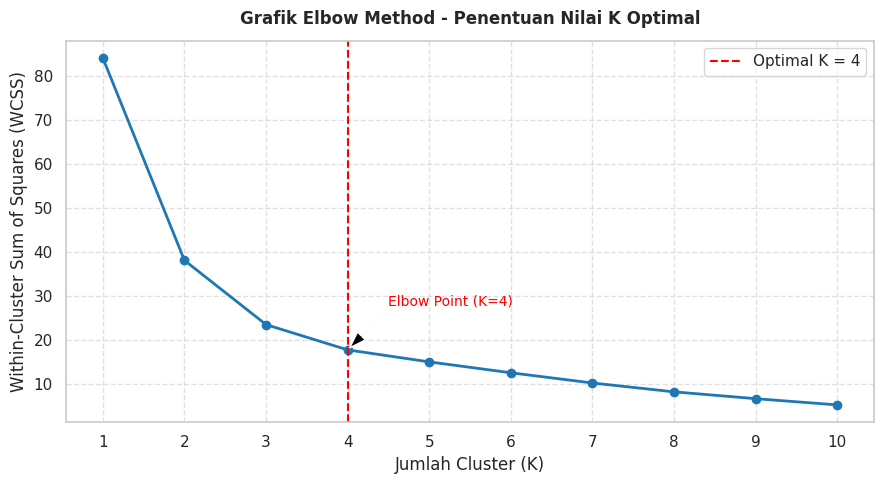

In [ ]:
print("--- TAHAP 5.1: DATA MINING (ELBOW METHOD EVALUATION) ---")

wcss = []
K_MAX = 10

for i in range(1, K_MAX + 1):
    kmeans_test = KMeans(n_clusters=i, init='k-means++', n_init=10, random_state=42)
    kmeans_test.fit(X_scaled)
    wcss.append(kmeans_test.inertia_)

# Render Plot Grafik Siku
plt.figure(figsize=(9, 5))
plt.plot(range(1, K_MAX + 1), wcss, marker='o', linestyle='-', color='#1f77b4', linewidth=2, markersize=6)
plt.title('Grafik Elbow Method - Penentuan Nilai K Optimal', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.xticks(np.arange(1, K_MAX + 1, 1))
plt.grid(True, linestyle='--', alpha=0.6)

# Menambahkan garis vertikal di titik 'elbow' yang dipilih (misalnya K=4)
elbow_k = 4 # Berdasarkan observasi visual dari kurva WCSS sebelumnya
plt.axvline(x=elbow_k, color='red', linestyle='--', linewidth=1.5, label=f'Optimal K = {elbow_k}')
plt.annotate(f'Elbow Point (K={elbow_k})',
             xy=(elbow_k, wcss[elbow_k-1]),
             xytext=(elbow_k + 0.5, wcss[elbow_k-1] + 10), # Sesuaikan posisi teks jika perlu
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=8),
             fontsize=10, color='red')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
print("--- TAHAP 5.2: DATA MINING (EKSEKUSI FINAL K-MEANS K=4) ---")

# Bangun model final dan injeksikan label klaster ke dataframe bersih
kmeans_final = KMeans(n_clusters=4, init='k-means++', n_init=20, max_iter=300, random_state=42)
df_clean['cluster'] = kmeans_final.fit_predict(X_scaled)

print("Algoritma K-Means berhasil mengunci pengelompokan populasi mahasiswa ke dalam 4 klaster.")

--- TAHAP 5.2: DATA MINING (EKSEKUSI FINAL K-MEANS K=4) ---
Algoritma K-Means berhasil mengunci pengelompokan populasi mahasiswa ke dalam 4 klaster.


In [ ]:
print("--- TAHAP 6.1: EVALUASI PROFILING KOORDINAT CENTROID ASLI ---")

# Transformasi balik dari skala Z-score ke besaran angka riil asli
centroids_original = scaler.inverse_transform(kmeans_final.cluster_centers_)
df_centroids = pd.DataFrame(centroids_original, columns=features)
df_centroids.index.name = 'Cluster ID'

print("\n[TABEL CENTROID FINAL - SALIN KE DALAM TEKS BAB IV]")
display(df_centroids.round(2))

print("\n[PROPORSI SEBARAN MAHASISWA PER KLASTER]")
cluster_counts = df_clean['cluster'].value_counts().sort_index()
# Gunakan cluster_mapping untuk mendapatkan nama label klaster
for cluster_id, count in cluster_counts.items():
    percentage = (count / len(df_clean)) * 100
    cluster_name = cluster_mapping.get(cluster_id, f'Cluster {cluster_id}') # Menggunakan .get untuk penanganan jika ID tidak ditemukan
    print(f"{cluster_name} : {count} Mahasiswa ({percentage:.2f}%)")

--- TAHAP 6.1: EVALUASI PROFILING KOORDINAT CENTROID ASLI ---

[TABEL CENTROID FINAL - SALIN KE DALAM TEKS BAB IV]


,kalori_konsumsi,bmr,tdee,status_kalori
Cluster ID,,,,
0,346.63,1557.45,2085.68,-1739.05
1,362.77,1672.99,2379.87,-2017.11
2,362.27,1948.67,2679.43,-2317.15
3,388.44,1392.62,1911.25,-1522.81



[PROPORSI SEBARAN MAHASISWA PER KLASTER]
Defisit Kalori Berat : 5 Mahasiswa (23.81%)
Defisit Kalori Ringan : 7 Mahasiswa (33.33%)
Gizi Seimbang (Normal) : 3 Mahasiswa (14.29%)
Surplus Kalori : 6 Mahasiswa (28.57%)


In [ ]:
print("--- TAHAP 6.2: MAPPING LABEL INTERPRETASI GIZI ---")

# Berdasarkan output [PROPORSI SEBARAN MAHASISWA PER KLASTER] dari TAHAP 6.1:
# Cluster ID 0 memiliki 5 mahasiswa -> akan diberi label 'Defisit Kalori Berat'
# Cluster ID 1 memiliki 7 mahasiswa -> akan diberi label 'Defisit Kalori Ringan'
# Cluster ID 2 memiliki 3 mahasiswa -> akan diberi label 'Gizi Seimbang (Normal)'
# Cluster ID 3 memiliki 6 mahasiswa -> akan diberi label 'Surplus Kalori'
cluster_mapping = {
    0: 'Defisit Kalori Berat',
    1: 'Defisit Kalori Ringan',
    2: 'Gizi Seimbang (Normal)',
    3: 'Surplus Kalori'
}

# Menerapkan nama label baru berdasarkan kolom cluster numerik
df_clean['cluster_label'] = df_clean['cluster'].map(cluster_mapping)

print("Pemetaan label tekstual sukses diterapkan. Kolom 'cluster_label' telah diperbarui.")
# Menampilkan sampel hasil pemetaan label
display(df_clean[['Nama Mahasiswa', 'status_kalori', 'cluster', 'cluster_label']].head())

--- TAHAP 6.2: MAPPING LABEL INTERPRETASI GIZI ---
Pemetaan label tekstual sukses diterapkan. Kolom 'cluster_label' telah diperbarui.


,Nama Mahasiswa,status_kalori,cluster,cluster_label
0,Nauval Azis Prasetio,-1547.357829,0,Defisit Kalori Berat
1,Vicky Ardiansyah,-2073.727571,1,Defisit Kalori Ringan
2,Ivan Kohandi,-2209.941631,2,Gizi Seimbang (Normal)
3,Defina Paridah,-1769.429226,0,Defisit Kalori Berat
4,Muhammad Alfa Fauzan,-2093.567887,1,Defisit Kalori Ringan


In [ ]:
display(df_clean.head())

,User ID,Nama Mahasiswa,gender,Berat Badan,Tinggi Badan,Umur,faktor_aktivitas,Karbo,Protein,Lemak,kalori_konsumsi,bmr,tdee,status_kalori,cluster,cluster_label
0,6a03242031722f1efa782353,Nauval Azis Prasetio,Male,60,170,20,1.200,48.196190,16.998095,11.692381,366.008571,1594.472,1913.366400,-1547.357829,0,Defisit Kalori Berat
1,6a0326bc31722f1efa782362,Vicky Ardiansyah,Male,75,168,21,1.375,54.492381,15.143333,10.604286,373.981429,1780.152,2447.709000,-2073.727571,1,Defisit Kalori Ringan
2,6a0327d831722f1efa782371,Ivan Kohandi,Male,78,177,21,1.375,46.135714,17.316190,10.956667,352.417619,1863.534,2562.359250,-2209.941631,2,Gizi Seimbang (Normal)
3,6a032d9431722f1efa782380,Defina Paridah,Female,71,165,21,1.375,44.799048,15.694762,9.400476,326.579524,1524.370,2096.008750,-1769.429226,0,Defisit Kalori Berat
4,6a032eb031722f1efa78238f,Muhammad Alfa Fauzan,Male,75,168,22,1.375,42.040952,18.712857,11.480000,346.335238,1774.475,2439.903125,-2093.567887,1,Defisit Kalori Ringan


In [ ]:
display(df_clean)

,User ID,Nama Mahasiswa,gender,Berat Badan,Tinggi Badan,Umur,faktor_aktivitas,Karbo,Protein,Lemak,kalori_konsumsi,bmr,tdee,status_kalori,cluster,cluster_label
0,6a03242031722f1efa782353,Nauval Azis Prasetio,Male,60,170,20,1.200,48.196190,16.998095,11.692381,366.008571,1594.472,1913.366400,-1547.357829,0,Defisit Kalori Berat
1,6a0326bc31722f1efa782362,Vicky Ardiansyah,Male,75,168,21,1.375,54.492381,15.143333,10.604286,373.981429,1780.152,2447.709000,-2073.727571,1,Defisit Kalori Ringan
2,6a0327d831722f1efa782371,Ivan Kohandi,Male,78,177,21,1.375,46.135714,17.316190,10.956667,352.417619,1863.534,2562.359250,-2209.941631,2,Gizi Seimbang (Normal)
3,6a032d9431722f1efa782380,Defina Paridah,Female,71,165,21,1.375,44.799048,15.694762,9.400476,326.579524,1524.370,2096.008750,-1769.429226,0,Defisit Kalori Berat
4,6a032eb031722f1efa78238f,Muhammad Alfa Fauzan,Male,75,168,22,1.375,42.040952,18.712857,11.480000,346.335238,1774.475,2439.903125,-2093.567887,1,Defisit Kalori Ringan
5,6a032fc331722f1efa78239e,Widia Winata Putri,Female,45,155,21,1.375,48.903333,19.529048,11.547619,377.658095,1252.968,1722.831000,-1345.172905,3,Surplus Kalori
6,6a03308731722f1efa7823ad,Nur Laili Kamalin,Female,88,165,21,1.375,45.582381,19.580952,10.719048,357.124762,1681.569,2312.157375,-1955.032613,1,Defisit Kalori Ringan
7,6a0337d70ebbc030ff57cd93,Levina Hilmaputri Hendriani,Female,60,179,22,1.375,52.346667,13.945238,9.565238,351.254762,1461.695,2009.830625,-1658.575863,0,Defisit Kalori Berat
8,6a033a890ebbc030ff57cda2,Nala Raihansyah,Female,80,160,21,1.375,46.720952,16.034286,10.338095,344.063810,1592.103,2189.141625,-1845.077815,0,Defisit Kalori Berat
9,6a033c740ebbc030ff57cdb4,Thoriq Syauqi,Male,85,173,20,1.375,49.823333,17.400476,10.829048,366.356667,1943.794,2672.716750,-2306.360083,2,Gizi Seimbang (Normal)


--- TAHAP 6.3: VISUALISASI SEBARAN POLA KLASTER MAHASISWA UMB ---


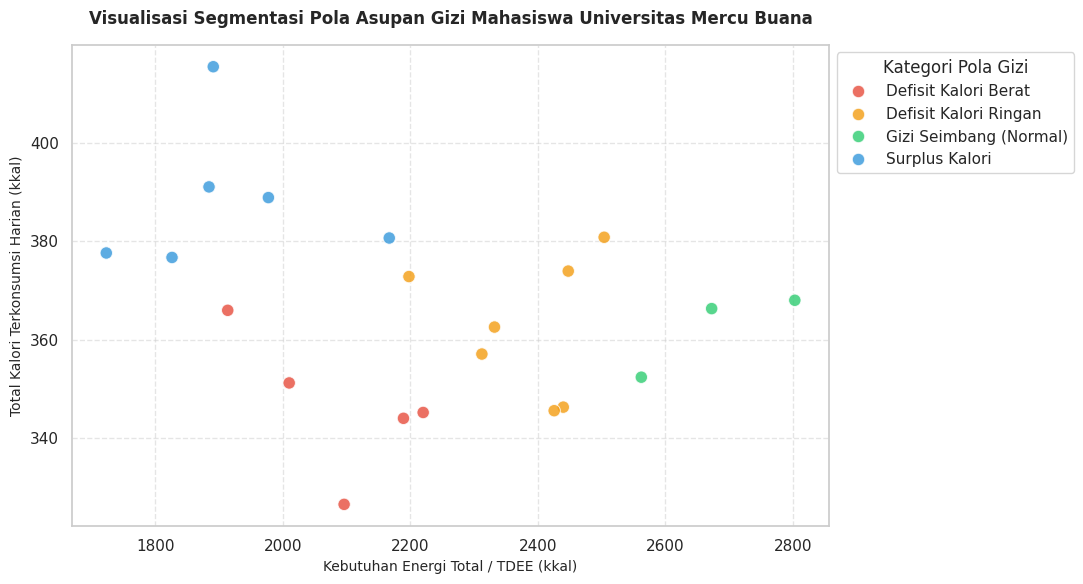

In [ ]:
print("--- TAHAP 6.3: VISUALISASI SEBARAN POLA KLASTER MAHASISWA UMB ---")

plt.figure(figsize=(11, 6))

# Menentukan urutan visualisasi di legenda agar rapi berurutan
order_labels = ['Defisit Kalori Berat', 'Defisit Kalori Ringan', 'Gizi Seimbang (Normal)', 'Surplus Kalori']

sns.scatterplot(
    data=df_clean,
    x='tdee',
    y='kalori_konsumsi',
    hue='cluster_label',      # Mengubah warna berdasarkan label teks gizi
    hue_order=order_labels,   # Mengunci urutan legenda agar terstruktur
    palette={'Defisit Kalori Berat': '#e74c3c',    # Merah
             'Defisit Kalori Ringan': '#f39c12',   # Oranye
             'Gizi Seimbang (Normal)': '#2ecc71',  # Hijau
             'Surplus Kalori': '#3498db'},         # Biru
    alpha=0.8,
    edgecolor='w',
    s=80
)

plt.title('Visualisasi Segmentasi Pola Asupan Gizi Mahasiswa Universitas Mercu Buana', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Kebutuhan Energi Total / TDEE (kkal)', fontsize=10)
plt.ylabel('Total Kalori Terkonsumsi Harian (kkal)', fontsize=10)
plt.legend(title='Kategori Pola Gizi', loc='upper left', bbox_to_anchor=(1, 1)) # Memindahkan legenda ke luar grafik agar rapi
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

--- TAHAP 6.4: VISUALISASI DISTRIBUSI KLASTER ---



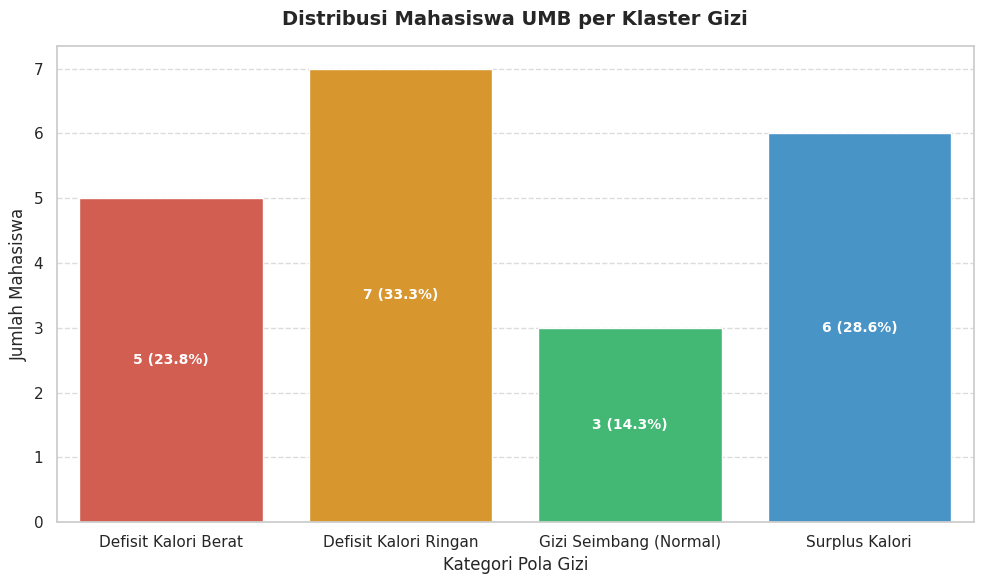

Visualisasi distribusi klaster telah berhasil dibuat.


In [ ]:
print("--- TAHAP 6.4: VISUALISASI DISTRIBUSI KLASTER ---\n")

# Menghitung jumlah mahasiswa per klaster dan persentasenya
cluster_distribution = df_clean['cluster_label'].value_counts()
cluster_percentage = df_clean['cluster_label'].value_counts(normalize=True) * 100

# Membuat DataFrame untuk visualisasi
df_cluster_dist = pd.DataFrame({
    'Cluster': cluster_distribution.index,
    'Jumlah Mahasiswa': cluster_distribution.values,
    'Persentase': cluster_percentage.values
})

# Urutkan berdasarkan order_labels yang sudah didefinisikan sebelumnya
df_cluster_dist['Cluster'] = pd.Categorical(df_cluster_dist['Cluster'], categories=order_labels, ordered=True)
df_cluster_dist = df_cluster_dist.sort_values('Cluster')

# Visualisasi Bar Chart
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x='Cluster',
    y='Jumlah Mahasiswa',
    data=df_cluster_dist,
    palette={'Defisit Kalori Berat': '#e74c3c',
             'Defisit Kalori Ringan': '#f39c12',
             'Gizi Seimbang (Normal)': '#2ecc71',
             'Surplus Kalori': '#3498db'},
    edgecolor='w'
)

# Menambahkan label persentase di dalam setiap bar, di tengah
for index, p in enumerate(ax.patches):
    height = p.get_height()
    # Mengambil data yang sesuai dari df_cluster_dist berdasarkan urutan bar
    current_cluster_data = df_cluster_dist.iloc[index]
    jumlah_mahasiswa = current_cluster_data['Jumlah Mahasiswa']
    persentase = current_cluster_data['Persentase']

    ax.text(p.get_x() + p.get_width() / 2, # x-coordinate tengah bar
            height / 2,                      # y-coordinate (tengah tinggi bar)
            f"{int(jumlah_mahasiswa)} ({persentase:.1f}%)", # Teks label
            color='white', ha="center", va='center', fontsize=10, fontweight='bold')

plt.title('Distribusi Mahasiswa UMB per Klaster Gizi', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Kategori Pola Gizi', fontsize=12)
plt.ylabel('Jumlah Mahasiswa', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("Visualisasi distribusi klaster telah berhasil dibuat.")